In [ ]:
### 
import os
import cv2
import sys
import time
import time
import torch
import random
import argparse
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
from pathlib import Path
from typing import Union, List
import matplotlib.pyplot as plt
import torch.nn.functional as F
from importlib.resources import files
from torchvision.transforms import v2
from transformers.image_utils import load_image
from transformers import AutoImageProcessor, AutoModel
# 将目标模块的父目录添加到 Python 搜索路径
module_path = './sam3' 
if module_path not in sys.path:
    sys.path.append(module_path)

from sam3.model.box_ops import box_xyxy_to_cxcywh
from sam3.visualization_utils import  normalize_bbox
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

def make_transform(resize_size: Union[int, List[int]] = 768): #[h, w]
    if isinstance(resize_size, int):
        target_size = (resize_size, resize_size)
    elif isinstance(resize_size, list) and len(resize_size) == 2:
        # Pytorch transforms v2.Resize 期望的格式通常是 (H, W) 或 (W, H)
        target_size = tuple(resize_size)
    else:
        raise ValueError("resize_size must be an integer or a list of two integers")
    
    to_tensor = v2.ToImage()
    resize = v2.Resize(target_size, antialias=True)
    to_float = v2.ToDtype(torch.float32, scale=True)
    normalize = v2.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    )
    return v2.Compose([to_tensor, resize, to_float, normalize])


def get_dino_features(image_path: str, model):
    image = load_image(image_path)
    W, H = image.size  # PIL Image: size is (width, height)

    patch_size = model.config.patch_size
    # print("Patch size:", patch_size)
    num_register_tokens = model.config.num_register_tokens
    pH = (H // patch_size) * patch_size
    pW = (W // patch_size) * patch_size
    transform = make_transform([(H // patch_size) * patch_size, (W // patch_size) * patch_size])

    inputs = transform(image).unsqueeze(0).to(model.device)

    with torch.inference_mode():
        outputs = model(inputs, output_hidden_states=True, interpolate_pos_encoding=True)
        # 直接从模型输出获取patch特征（去掉CLS token）
        patch_features = outputs.last_hidden_state[:, 1 + num_register_tokens:, :]  # 去掉CLS token
       
    feature_map = patch_features.reshape(1, pH // patch_size, pW // patch_size, -1).permute(0, 3, 1, 2)  # (1, C, H', W')
    return feature_map, (pW, pH), image

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    # 确保 PyTorch 卷积等操作是确定性的（会牺牲一点速度）
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 从分类目录中获取多个mask和box
def get_cls_mask_and_box(cls_path="/data/yilong/Datasets/R2C7K/Ref/Images/Cat", processor=None, num_samples=5):
    class_name = os.path.basename(cls_path)
    candidates = {True: [], False: []} # True: single target, False: multiple targets
    selected_paths = set() # 记录已选中的路径，避免重复
    if processor:
        processor.set_confidence_threshold(0.5)
    # 定义两次尝试的 Prompts
    prompts_to_try = [class_name, "visual"]
    for current_prompt in prompts_to_try:
        # 如果已经集齐了足够的单目标样本，或者总数已够，可以根据需求提前跳出
        if len(candidates[True]) + len(candidates[False]) >= num_samples:
            break
        for img_file in os.listdir(cls_path):
            img_path = os.path.join(cls_path, img_file)
            if img_path in selected_paths: continue # 跳过已选图片
            # 推理逻辑
            state = processor.set_text_prompt(prompt=current_prompt, state=processor.set_image(Image.open(img_path)))
            masks = state.get('masks', [])
            if len(masks) == 0: continue
            # 计算 Bounding Box
            any_mask = torch.any(masks, dim=0)
            coords = torch.where(any_mask)
            # 兼容不同维度的 coords 输出 (SAM3 输出通常在 [1, H, W] 或 [H, W])
            y_idx, x_idx = coords[-2], coords[-1]
            merged_box = [int(x_idx.min()), int(y_idx.min()), int(x_idx.max()), int(y_idx.max())]

            # 存储并标记
            is_single = (len(masks) == 1)
            candidates[is_single].append((img_path, state['unsampled_masks'], merged_box))
            selected_paths.add(img_path)
            # 如果单目标图片已经够了，直接收工
            if len(candidates[True]) >= num_samples:
                break
    # 按优先级合并结果
    result = (candidates[True] + candidates[False])[:num_samples]
    if not result: return [], [], []
    return [list(x) for x in zip(*result)]
# 获取sam3状态提示(encode boxes)
def get_sam3_state_prompt(image_path: str,
                          box: list,
                          processor,
                          unsampled_mask):
    ref_image = Image.open(image_path)
    w1, h1 = ref_image.size
    state1 = processor.set_image(ref_image) 
    state1['unsampled_masks'] = unsampled_mask
    box_xyxy = torch.tensor(box).view(-1, 4)
    box_cxcywh = box_xyxy_to_cxcywh(box_xyxy)
    norm_box = normalize_bbox(box_cxcywh, w1, h1).flatten().tolist()
    # processor.set_confidence_threshold(0.4)

    text_prompt = 'visual'
    # text_prompt =  f"{image_path.split('/')[-2]}"
    state1 = processor.extract_exemplar_visual_feature_v2(
        box=norm_box,
        label=True,
        state=state1,
        text_prompt = text_prompt # add class name as text prompt
    )
    return state1

def inference_image_by_state(image_path: str,
                             processor,
                             prompt_state):
    """
    使用给定的prompt_state对图像进行推理
    Args:
        image_path: 图像路径
        processor: Sam3Processor实例
        prompt_state: 预先计算的提示状态
    Returns:
        canadidate_mask_list: 包含掩码、分数和边界框的列表
    """
    image = Image.open(image_path)
    state = processor.set_image(image)
    # state['prompt'] = prompt_state['prompt']
    # state['prompt_mask'] = prompt_state['prompt_mask']
    state["txt_feats"] = prompt_state["txt_feats"]
    state["txt_masks"] = prompt_state["txt_masks"]
    state["geo_feats"] = prompt_state["geo_feats"]
    state["geo_masks"] = prompt_state["geo_masks"]
    state["visual_prompt_embed"] = prompt_state["visual_prompt_embed"]
    state["visual_prompt_mask"] = prompt_state["visual_prompt_mask"]
    state["boxes_embed"] = prompt_state["boxes_embed"]
    
    state = processor._forward_grounding_by_vision(state=state)
    canadidate_mask_list = []
    for i in range(len(state['masks'])):
        curr_mask = state['masks'][i]#.cpu().numpy()
        curr_socres = state['scores'][i]#.cpu().numpy()
        curr_box = state['boxes'][i]#.cpu().numpy()
        canadidate_mask_list.append({
            'masks': curr_mask,
            'scores': curr_socres,
            'boxes': curr_box
        })
    return canadidate_mask_list

      
def ref_fg_tar_mask_filter(
    ref_img_path,
    ref_mask_list,
    dino_model,
    target_feat_map,
    canadidate_list,
):
    # Product-of-Experts Scoring
    t0 = time.time()
    device = target_feat_map.device
    target_dtype = target_feat_map.dtype
    
    # 1. 提取并缓存参考特征 (Reference Prototype)
    with torch.inference_mode():
        ref_dinov2_feat, (pw, ph), _ = get_dino_features(ref_img_path, dino_model)
    _, C, H, W = ref_dinov2_feat.shape
    
    boolean_mask = [(m > 0) for m in ref_mask_list]
    ref_mask_full = torch.stack(boolean_mask, dim=0).any(dim=0).float().to(device)
    ref_mask_resized = F.interpolate(ref_mask_full.unsqueeze(0).unsqueeze(0), size=(H, W), mode='bilinear').squeeze()
    
    ref_feat_flat = ref_dinov2_feat.view(C, -1)
    ref_mask_flat = (ref_mask_resized > 0).view(-1)
    ref_feat_resized = ref_feat_flat[:, ref_mask_flat].mean(dim=1, keepdim=True).t() # [1, C]
    ref_feat_norm = F.normalize(ref_feat_resized, p=2, dim=1)

    # 2. 计算 Target Image 的全图 Similarity Heatmap (用于 PMI 和 Pearson)
    _, _, H_t, W_t = target_feat_map.shape
    tar_feat_flat = target_feat_map.view(C, -1) # [C, H_t*W_t]
    tar_feat_norm = F.normalize(tar_feat_flat, p=2, dim=0) # 对每个 patch 归一化
    # 全图热图: [1, H_t*W_t]
    global_heatmap = torch.mm(ref_feat_norm, tar_feat_norm).view(1, 1, H_t, W_t)
    
    t1 = time.time()

    # 3. 准备结果
    candidate_data_with_corr = {"scores": [], "boxes": [], "masks": [], "sims": []}
    num_masks = len(canadidate_list["masks"])
    
    if num_masks > 0:
        all_masks = torch.stack(canadidate_list["masks"], dim=0).to(device).to(target_dtype)
        if all_masks.ndim == 3: all_masks = all_masks.unsqueeze(1)
        all_masks_res = F.interpolate(all_masks, size=(H_t, W_t), mode='bilinear', align_corners=True)
        all_masks_flat = (all_masks_res > 0.5).to(target_dtype).view(num_masks, -1) # [N, HW]

        # --- 指标 A: Area-Weighted Average Similarity (AWAS) ---
        # 实际上就是 Mask 区域内热图的均值
        sum_sim = torch.mm(all_masks_flat, global_heatmap.view(-1, 1))
        counts = all_masks_flat.sum(dim=1, keepdim=True) + 1e-8
        awas_scores = (sum_sim / counts).squeeze(-1) # [N]

        # --- 指标 B: Point-wise Mutual Information (PMI) ---
        # 衡量 Mask 内平均响应 vs 全图平均响应
        global_avg_sim = global_heatmap.mean() + 1e-8
        pmi_scores = torch.log(awas_scores / global_avg_sim)
        # pmi_scores = awas_scores / global_avg_sim

        candidate_data_with_corr["scores"] = canadidate_list["scores"]
        candidate_data_with_corr["boxes"] = canadidate_list["boxes"]
        candidate_data_with_corr["masks"] = canadidate_list["masks"]
        # candidate_data_with_corr["sims"] = np.nan_to_num(pearson_scores.cpu().numpy(), nan=-1.0).tolist()
        candidate_data_with_corr["sims"] = np.nan_to_num(pmi_scores.cpu().numpy(), nan=-1.0).tolist()
        # --- 可视化 (Heatmap 叠加展示) ---

    t2 = time.time()

    # --- 可视化 (Heatmap 叠加展示) ---
    plt.close('all') # 释放内存
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    _ = axs[0].imshow(cv2.cvtColor(cv2.imread(ref_img_path), cv2.COLOR_BGR2RGB))
    _ = axs[0].set_title("Ref Image")
    _ = axs[1].imshow(ref_mask_resized.cpu().numpy(), cmap='gray')
    _ = axs[1].set_title("Ref Mask (Resized)")
    # 展示全图 Similarity Heatmap
    im = axs[2].imshow(global_heatmap.squeeze().cpu().numpy(), cmap='jet')
    _ = axs[2].set_title("Target Similarity Heatmap")
    plt.show()

    plt.imshow(global_heatmap.squeeze().cpu().numpy(), cmap='jet')
    plt.axis('off')
    plt.savefig(f'figs/cosin-sim-{ref_img_path.split("/")[-1]}', dpi=300, bbox_inches='tight', pad_inches=0)

    fig, axs = plt.subplots(1, len(candidate_data_with_corr['masks']), figsize=(15,5))

    if len(candidate_data_with_corr['masks']) == 1:
    # 如果只有一个子图，axs 是一个 Axes 对象，我们将其放入一个 NumPy 数组中
        axs = np.array([axs])
    else:
        # 如果有多个子图，axs 是一个 NumPy 数组，我们可以直接扁平化它
        axs = axs.flatten()
    idx = 0 
    for ax in axs:
        ax.imshow(candidate_data_with_corr['masks'][idx].cpu().squeeze().numpy())
        ax.set_title(f"{candidate_data_with_corr['sims'][idx]:.3f}")
        ax.axis('off')
        idx += 1
    plt.show()
    # print(f"特征提取: {t1-t0:.4f}s | 指标计算与可视化: {t2-t1:.4f}s | 总计: {t2-t0:.4f}s")
    return candidate_data_with_corr


def transform_list_dict_to_dict_list(data_list_dict):
    """
    将 [{masks: m1, boxes: b1, scores: s1},
         {masks: m2, boxes: b2, scores: s2}]
    转换为 {masks: [m1, m2], boxes: [b1, b2], scores: [s1, s2]}。
    Args:
        data_list_dict (list): 一个列表，其中每个元素都是一个字典，
                               字典包含 'masks', 'boxes', 'scores' 键。
    Returns:
        dict: 一个字典，其中键是 'masks', 'boxes', 'scores'，
              值是对应所有字典中这些键的列表。
              如果输入列表为空，则返回 {masks: [], boxes: [], scores: []}。
    """
    # 初始化结果字典，每个键对应一个空列表
    transformed_data = {
        "masks": [],
        "boxes": [],
        "scores": [],
        "sims": []
    }
    # 如果输入列表为空，直接返回初始化的空字典
    if not data_list_dict:
        return transformed_data
    # 遍历输入的列表中的每一个字典
    for item_dict in data_list_dict:
        # 尝试获取每个键的值并添加到对应的列表中
        if "masks" in item_dict:
            transformed_data["masks"].append(item_dict["masks"])
        if "boxes" in item_dict:
            transformed_data["boxes"].append(item_dict["boxes"])
        if "scores" in item_dict:
            transformed_data["scores"].append(item_dict["scores"])
        if "sims" in item_dict:
            transformed_data["sims"].append(item_dict["sims"])
    return transformed_data

    
def pipeline_signle_image(
    ref_img_paths,
    ref_masks,
    ref_boxes,
    target_image_path,
    processor,
    dino_model,
):
    final_filtered_results = {
        "scores": [],
        "boxes": [],
        "masks": [],
        "sims": []
    }
    target_feat_map, _, _ = get_dino_features(target_image_path, dino_model)
    for i in range(len(ref_img_paths)):
        # print(f"Reference Image {i}: {ref_img_paths[i]}, Box: {ref_boxes[i]}")
        # Get sam3 state prompt
        prompt_state = get_sam3_state_prompt(
            image_path=ref_img_paths[i],
            box=ref_boxes[i],
            processor=processor,
            unsampled_mask=ref_masks[i]
        )
        # Inference target image by state prompt
        curr_canadidate_mask_list = inference_image_by_state(
            image_path=target_image_path,
            processor=processor,
            prompt_state=prompt_state
        )
        canadidate_mask_list = transform_list_dict_to_dict_list(curr_canadidate_mask_list)
        if len(canadidate_mask_list['masks'])==0:
            continue
        filtered_results = ref_fg_tar_mask_filter(ref_img_path=ref_img_paths[i],
                               ref_mask_list=ref_masks[i],
                               dino_model=dino_model,
                               target_feat_map=target_feat_map,
                               canadidate_list=canadidate_mask_list)

        final_filtered_results["scores"].extend(filtered_results["scores"])
        final_filtered_results["boxes"].extend(filtered_results["boxes"])
        final_filtered_results["masks"].extend(filtered_results["masks"])
        final_filtered_results["sims"].extend(filtered_results["sims"])
        
    return final_filtered_results

def select_top_k(candidate, k):
    FINAL = {"scores": [], "boxes": [], "masks": [], "sims": []}
    
    if not candidate["sims"]:
        return FINAL

    # 1. 排序并取 Top-K
    keys = ["scores", "boxes", "masks", "sims"]
    items = zip(*[candidate[key] for key in keys])
    sorted_items = sorted(items, key=lambda x: x[3], reverse=True)[:k]
    
    # 2. 解包
    unzipped = list(zip(*sorted_items))
    for i, key in enumerate(keys):
        FINAL[key] = list(unzipped[i])

    # 3. 根据 Mask 重新计算 Bounding Box (Top-Left & Bottom-Right)
    new_boxes = []
    for mask in FINAL["masks"]:
        # 确保 mask 是 2D 格式 (H, W)
        if torch.is_tensor(mask):
            m = mask.squeeze()
            # 找到所有非零像素的坐标
            coords = torch.nonzero(m)
            if coords.shape[0] > 0:
                # y 是 dim 0, x 是 dim 1
                ymin, xmin = coords.min(dim=0).values
                ymax, xmax = coords.max(dim=0).values
                new_box = torch.tensor([xmin, ymin, xmax, ymax], device=mask.device)
            else:
                new_box = torch.tensor([0, 0, 0, 0], device=mask.device)
        else:
            # Numpy 处理逻辑
            m = np.squeeze(mask)
            coords = np.argwhere(m > 0)
            if coords.size > 0:
                ymin, xmin = coords.min(axis=0)
                ymax, xmax = coords.max(axis=0)
                new_box = np.array([xmin, ymin, xmax, ymax])
            else:
                new_box = np.array([0, 0, 0, 0])
        
        new_boxes.append(new_box)
    
    # 更新 FINAL 中的 boxes
    FINAL["boxes"] = new_boxes
    # FINAL = connected_block_filter(FINAL)
    return FINAL

def run_inference_on_r2c7k(test_imgs_dir="/data/yilong/Datasets/R2C7K/Camo/test/Imgs/", 
                           output_dir="/data/thetian/Tiny_COD/results/pred/sam3withvision",
                           processor=None, dino_model=None, k=1, n_ref=5, n_chunks=None, chunk_idx=None, refine=True):
    output_root = Path(output_dir)
    output_root.mkdir(parents=True, exist_ok=True)
    ref_root = "/data/yilong/Datasets/R2C7K/Ref/Images/"
    
    # --- 初始化 Log 文件 ---
    log_file_path = output_root / f"inference_log_{time.strftime('%Y%m%d_%H%M%S')}.txt"
    def log_message(msg):
        with open(log_file_path, "a") as f:
            f.write(f"[{time.strftime('%H:%M:%S')}] {msg}\n")
    
    log_message(f"Starting inference on {test_imgs_dir}")
    # -----------------------

    all_tasks = []
    class_dirs = [d for d in os.listdir(test_imgs_dir) if os.path.isdir(os.path.join(test_imgs_dir, d))]
    # class_dirs.sort()
    class_dirs.sort(reverse=True)

    
    for class_dir in class_dirs:
        class_path = os.path.join(test_imgs_dir, class_dir)
        img_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        for img_file in img_files:
            all_tasks.append((class_dir, img_file))

    fail_count = 0
    skip_count = 0
    current_ref_class = None
    ref_data = (None, None, None)

    if n_chunks is not None and chunk_idx is not None:
        if chunk_idx >= n_chunks:
            raise ValueError(f"chunk_idx {chunk_idx} 必须小于 n_chunks {n_chunks}")
            
        # 计算每个块的大小
        total_tasks = len(all_tasks)
        chunk_size = (total_tasks + n_chunks - 1) // n_chunks  # 向上取整
        
        start_idx = chunk_idx * chunk_size
        end_idx = min(start_idx + chunk_size, total_tasks)
        
        all_tasks = all_tasks[start_idx:end_idx]
        print(f"Parallel Mode: Processing chunk {chunk_idx}/{n_chunks} (Tasks: {start_idx}-{end_idx})")
    else:
        print(f"Standard Mode: Processing all {len(all_tasks)} tasks")


    pbar = tqdm(all_tasks, desc="Total Inference Progress", unit="img", ncols=120)

    for class_dir, img_file in pbar:
        pbar.set_description(f"Processing: {class_dir}")
        class_output_dir = output_root / class_dir
        class_output_dir.mkdir(parents=True, exist_ok=True)
        mask_save_path = class_output_dir / f"{img_file.rsplit('.', 1)[0]}.png"
        
        if mask_save_path.exists():
            skip_count += 1
            continue

        if class_dir != current_ref_class:
            ref_dir_path = os.path.join(ref_root, class_dir)
            ref_data = get_cls_mask_and_box(cls_path=ref_dir_path, processor=processor, num_samples=n_ref)
            current_ref_class = class_dir
            log_message(f"Switched to class: {class_dir}")
        
        ref_img_paths, ref_masks, ref_boxes = ref_data
        target_image_path = os.path.join(test_imgs_dir, class_dir, img_file)

        # try:

        tgt_image = Image.open(target_image_path).convert("RGB")
        
        final_filtered_results = pipeline_signle_image(
            ref_img_paths=ref_img_paths,
            ref_masks=ref_masks,
            ref_boxes=ref_boxes,
            target_image_path=target_image_path,
            processor=processor,
            dino_model=dino_model,
        )

        FINAL = select_top_k(final_filtered_results, k)
        original_size = tgt_image.size[::-1]
        mask_np = np.zeros(original_size, dtype=np.uint8)

        if refine:
            if 'masks' in FINAL and len(FINAL['masks']) > 0:
                width, height = tgt_image.size
                box_input = [item.tolist() for item in FINAL['boxes']]
                box_input_cxcywh = box_xyxy_to_cxcywh(torch.tensor(box_input).view(-1,4))
                norm_boxes_cxcywh = normalize_bbox(box_input_cxcywh, width, height).tolist()
                # fixed
                box_labels = [True] * len(box_input)

                processor.set_confidence_threshold(0.35)
                inference_state = processor.set_image(tgt_image)
                inference_state = processor.set_text_prompt(current_ref_class, state=inference_state)
                for box, label in zip(norm_boxes_cxcywh, box_labels):
                    inference_state = processor.add_geometric_prompt( 
                        state=inference_state, box=box, label=label
                    )
                combined_mask = torch.zeros(original_size, dtype=torch.bool, device='cuda')
                # print(f'len of original pred: {len(inference_state["masks"])}')
                for mask in inference_state["masks"]:
                    combined_mask = combined_mask | mask.squeeze(0)  # 假设 mask 是 [1, H, W]
                
                mask_np = combined_mask.cpu().numpy().astype(np.uint8) * 255
            else:
                fail_count += 1
                log_message(f"FAIL: Zero objects detected in {target_image_path}")
        else: 
            # masks_list = final_filtered_results['masks']
            masks_list = FINAL['masks']
            if len(masks_list) > 0:
                stacked_masks = torch.cat(masks_list, dim=0)
                mask_torch, _ = torch.max(stacked_masks, dim=0)
                mask_np = mask_torch.cpu().numpy().astype(np.uint8) * 255
                # print(mask_np.shape)
            else:
                fail_count += 1
                log_message(f"FAIL: Zero objects detected in {target_image_path}")

        Image.fromarray(mask_np).save(mask_save_path)

        # except Exception as e:
        #     fail_count += 1
        #     log_message(f"ERROR: {target_image_path} | Exception: {str(e)}")
        
        pbar.set_postfix(skip=skip_count, fail=fail_count)

    log_message(f"Completed. Total Failed: {fail_count}, Total Skipped: {skip_count}")
    print(f"Log saved to {log_file_path}")

# 🔧 使用示例



In [ ]:
device = "cuda"
bpe_path = "./sam3/assets/bpe_simple_vocab_16e6.txt.gz"
checkpoint_path = "./hf_sam3/sam3.pt"  # 请从这里下载权重、配置文件后放在hf_sam3目录下：https://www.modelscope.cn/models/facebook/sam3/files 
model = build_sam3_image_model(bpe_path=bpe_path, checkpoint_path=checkpoint_path, device=device)
processor = Sam3Processor(model, confidence_threshold=0.5)
dinov3_path = "./hf-dinov3" # 请从这里下载权重、配置文件后放在hf-dinov3目录下：https://www.modelscope.cn/models/facebook/dinov3-vitb16-pretrain-lvd1689m/files 
dino_model = AutoModel.from_pretrained(
    dinov3_path,
    dtype=torch.float16,
    attn_implementation="sdpa"
).to(device)
dino_model.eval()

Loading weights: 100%|██████████| 211/211 [00:00<00:00, 744.86it/s, Materializing param=norm.weight]                     


DINOv3ViTModel(
  (embeddings): DINOv3ViTEmbeddings(
    (patch_embeddings): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (rope_embeddings): DINOv3ViTRopePositionEmbedding()
  (layer): ModuleList(
    (0-11): 12 x DINOv3ViTLayer(
      (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attention): DINOv3ViTAttention(
        (k_proj): Linear(in_features=768, out_features=768, bias=False)
        (v_proj): Linear(in_features=768, out_features=768, bias=True)
        (q_proj): Linear(in_features=768, out_features=768, bias=True)
        (o_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (layer_scale1): DINOv3ViTLayerScale()
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (mlp): DINOv3ViTMLP(
        (up_proj): Linear(in_features=768, out_features=3072, bias=True)
        (down_proj): Linear(in_features=3072, out_features=768, bias=True)
        (act_fn): GELUActivation()
 

accquire ref_img_paths time: 2.36


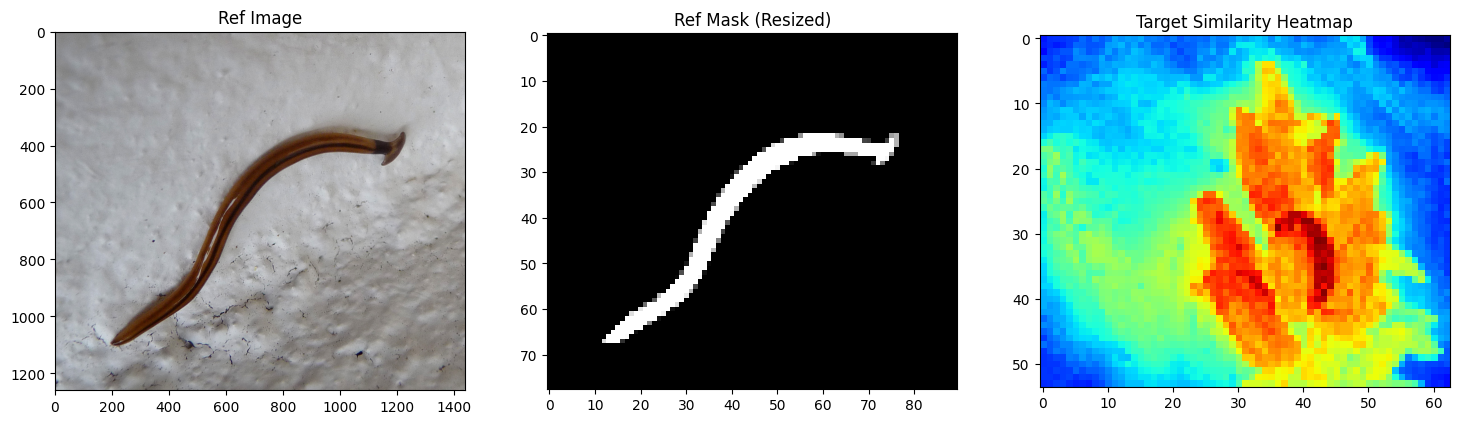

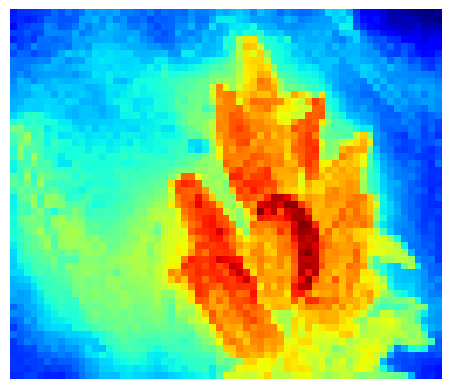

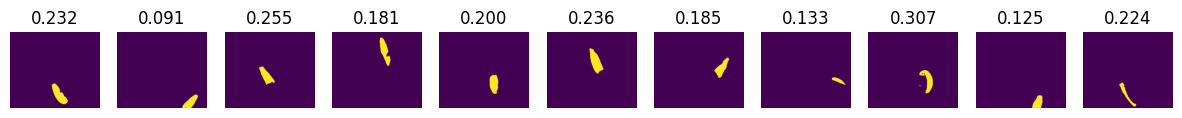

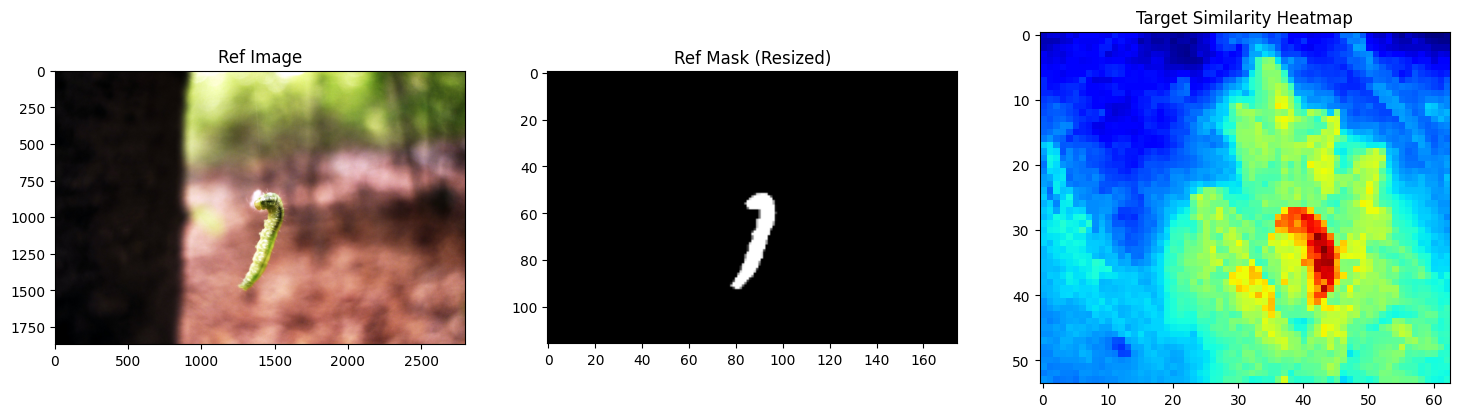

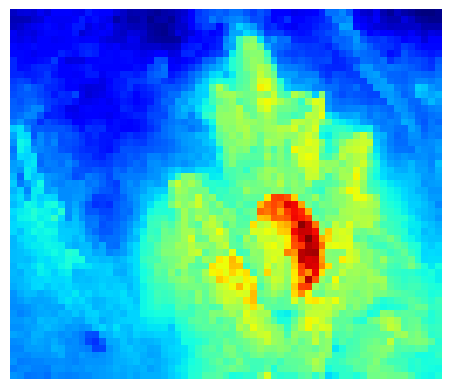

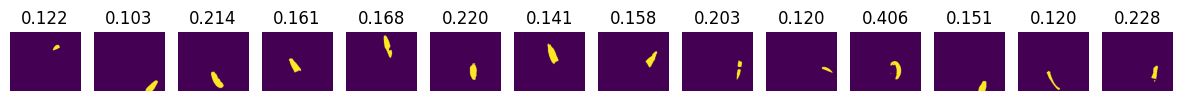

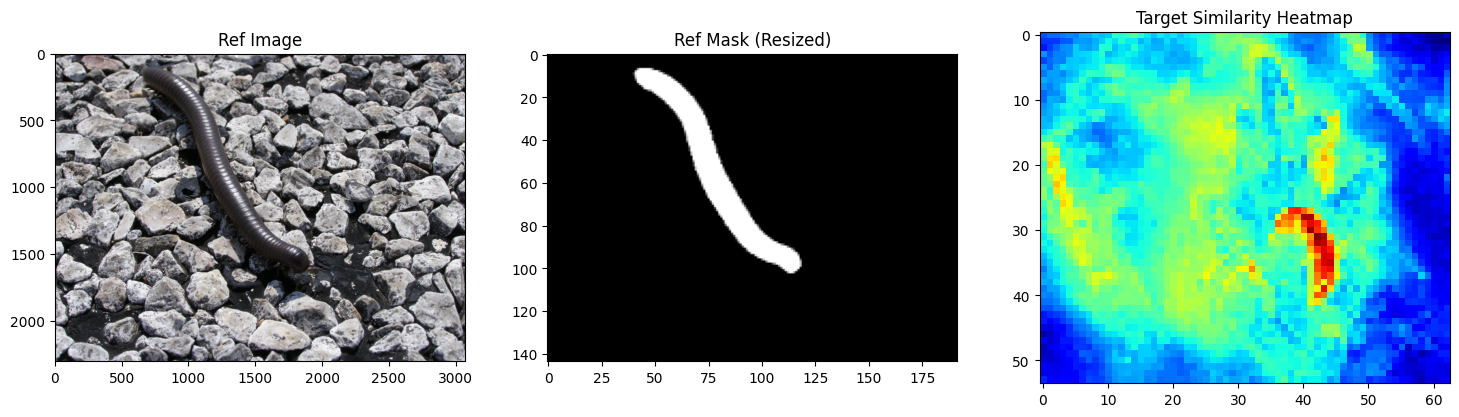

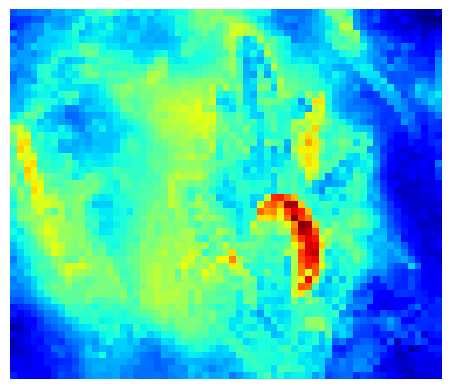

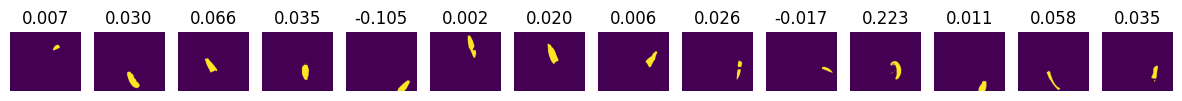

top-k time: 0.0
------------------------------------------------------------
[0.405517578125]
[tensor([579, 435, 736, 701], device='cuda:0')]
found 1 object(s)
refine time: 0.07
summed time: 13.14
found 7 object(s)


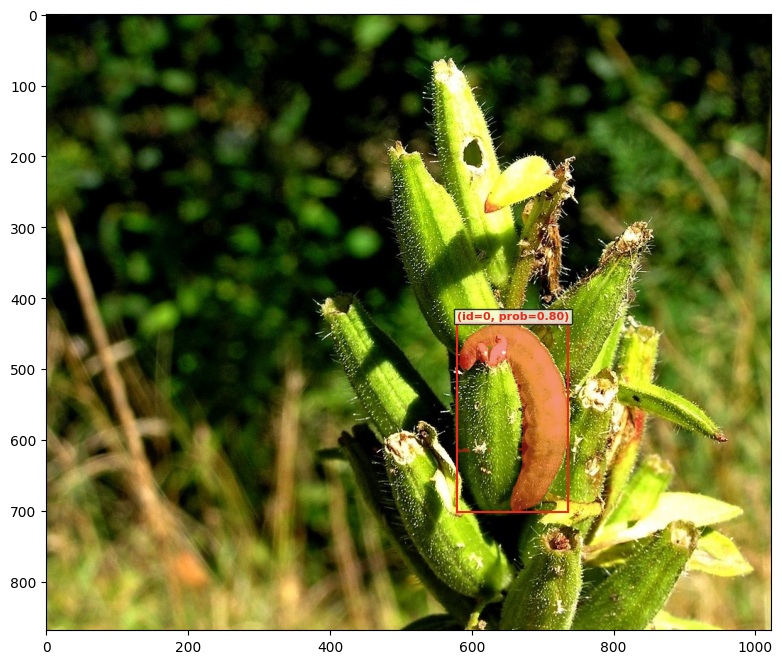

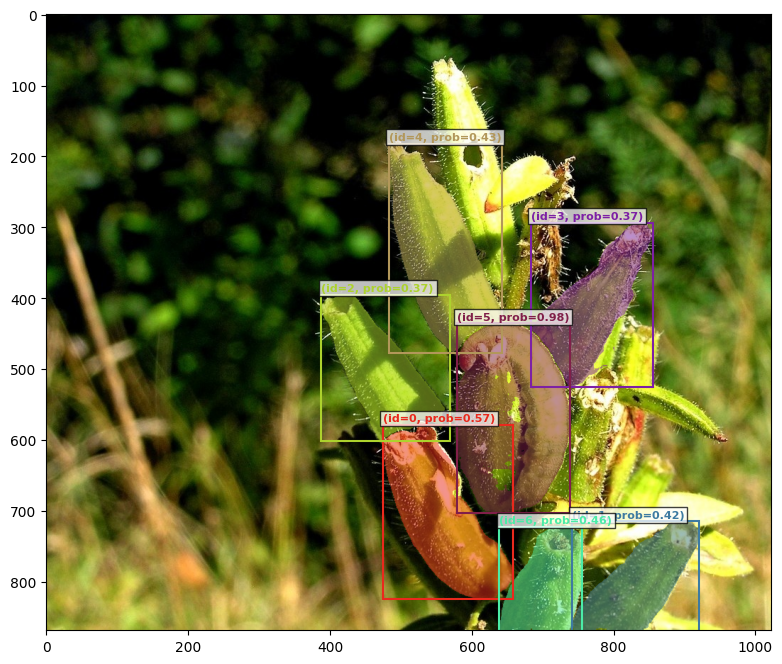

In [ ]:
from sam3.visualization_utils import draw_box_on_image, normalize_bbox, plot_results, plot_bbox
seed_everything(seed=43)

# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Cat/COD10K-CAM-2-Terrestrial-23-Cat-1431.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Caterpillar/COD10K-CAM-2-Terrestrial-24-Caterpillar-1644.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Spider/COD10K-CAM-2-Terrestrial-45-Spider-2529.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Shrimp/COD10K-CAM-1-Aquatic-16-Shrimp-1123.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/SeaHorse/COD10K-CAM-1-Aquatic-15-SeaHorse-1078.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/ScorpionFish/COD10K-CAM-1-Aquatic-14-ScorpionFish-935.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Rabbit/COD10K-CAM-2-Terrestrial-40-Rabbit-2340.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Giraffe/COD10K-CAM-2-Terrestrial-32-Giraffe-1942.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Cicada/COD10K-CAM-3-Flying-56-Cicada-3441.jpg"
target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Pipefish/COD10K-CAM-1-Aquatic-13-Pipefish-535.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Toad/COD10K-CAM-4-Amphibian-68-Toad-4951.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Dog/COD10K-CAM-2-Terrestrial-29-Dog-1817.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Reccoon/COD10K-CAM-2-Terrestrial-41-Reccoon-2374.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Frogmouth/COD10K-CAM-3-Flying-58-Frogmouth-3599.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Duck/COD10K-CAM-2-Terrestrial-30-Duck-1876.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Fish/COD10K-CAM-1-Aquatic-6-Fish-235.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Bird/COD10K-CAM-3-Flying-53-Bird-3221.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Flounder/COD10K-CAM-1-Aquatic-7-Flounder-270.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Bug/COD10K-CAM-2-Terrestrial-22-Bug-1262.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Bat/COD10K-CAM-3-Flying-50-Bat-2955.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/StickInsect/COD10K-CAM-2-Terrestrial-46-StickInsect-2858.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Butterfly/COD10K-CAM-3-Flying-55-Butterfly-3389.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/GhostPipefish/COD10K-CAM-1-Aquatic-9-GhostPipefish-369.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Human/COD10K-CAM-2-Terrestrial-34-Human-2014.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Wolf/COD10K-CAM-2-Terrestrial-48-Wolf-2921.jpg"
target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Worm/COD10K-CAM-2-Terrestrial-49-Worm-2930.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Cheetah/COD10K-CAM-2-Terrestrial-27-Cheetah-1742.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Katydid/COD10K-CAM-3-Flying-61-Katydid-4080.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Heron/COD10K-CAM-3-Flying-60-Heron-3912.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Toad/COD10K-CAM-4-Amphibian-68-Toad-4883.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Tiger/COD10K-CAM-2-Terrestrial-47-Tiger-2876.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/Snake/COD10K-CAM-2-Terrestrial-44-Snake-2461.jpg"
# target_image_path = "/data/yilong/Datasets/R2C7K/Camo/test/Imgs/LeafySeaDragon/COD10K-CAM-1-Aquatic-10-LeafySeaDragon-416.jpg"
ref_dir_path = "/data/yilong/Datasets/R2C7K/Ref/Images/"+target_image_path.split('/')[-2]



init_start = time.time()


start_1 = time.time()
ref_img_paths, ref_masks, ref_boxes = get_cls_mask_and_box(
    cls_path=ref_dir_path,
    processor=processor,
    num_samples=3
)
end_1 = time.time()
print(f'accquire ref_img_paths time: {round(end_1-start_1,2)}')


final_filtered_results = pipeline_signle_image(
    ref_img_paths=ref_img_paths,
    ref_masks=ref_masks,
    ref_boxes=ref_boxes,
    target_image_path=target_image_path,
    processor=processor,
    dino_model=dino_model
)

start_1 = time.time()
FINAL = select_top_k(final_filtered_results, 1)
end_1 = time.time()
print(f'top-k time: {round(end_1-start_1,2)}')

print('---'*20)
print(FINAL['sims'])
print(FINAL['boxes'])
# 可视化最终结果
plot_results(Image.open(target_image_path).convert("RGB"), FINAL)


# box 过滤
# final_filtered_results = apply_combined_filtering(final_filtered_results)
# plot_results(Image.open(target_image_path).convert("RGB"), final_filtered_results)


# original sam3 refine
img = Image.open(target_image_path)
width, height = img.size
box_input = [item.tolist() for item in FINAL['boxes']]
box_input_cxcywh = box_xyxy_to_cxcywh(torch.tensor(box_input).view(-1,4))
norm_boxes_cxcywh = normalize_bbox(box_input_cxcywh, width, height).tolist()

processor.set_confidence_threshold(0.35)
box_labels = [True] *len(box_input_cxcywh)
inference_state = processor.set_image(img)
# inference_state = processor.set_text_prompt(prompt=f"visual", state=inference_state)
inference_state = processor.set_text_prompt(prompt=f"{target_image_path.split('/')[-2]}", state=inference_state)

start_1 = time.time()
for box, label in zip(norm_boxes_cxcywh, box_labels):
    inference_state = processor.add_geometric_prompt(
        state=inference_state, box=box, label=label
    )
end_1 = time.time()
print(f'refine time: {round(end_1-start_1,2)}')

init_end = time.time()
print(f'summed time: {round(init_end-init_start,2)}')

plot_results(img, inference_state)
